# Analyze Helium line
from `jw03131-o001_t001_nirspec_g140h-f100lp_s3d`

### Load data and import funcitons

In [1]:
import project as p
import numpy as np
import matplotlib.pyplot as plt

p.load_data("data/fits/jw03131-o001_t001_nirspec_g140h-f100lp_s3d.fits")

Set DATE-AVG to '2024-02-19T07:34:54.885' from MJD-AVG.
Set DATE-END to '2024-02-19T08:28:30.725' from MJD-END'. [astropy.wcs.wcs]
Set OBSGEO-B to    19.316752 from OBSGEO-[XYZ].
Set OBSGEO-H to 1470239568.529 from OBSGEO-[XYZ]'. [astropy.wcs.wcs]


### Animation over spectrum

From QFitsView we can see spikes in the range $\lambda \in [1.08\mu m, 1.09\mu m]$ which may be helium.

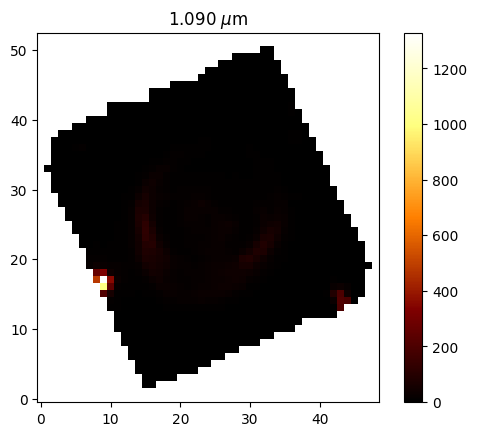

In [2]:
from matplotlib.animation import FuncAnimation
# from matplotlib.patches import Ellipse

num_frames = 20

wavelengths = np.linspace(1.08, 1.09, num_frames)

fig, ax = plt.subplots()

def image(frame):
    return p.get_image(p.spectrum_index(wavelengths[frame]))

im = ax.imshow(
    image(0),
    cmap="afmhot",
    animated=True,
    origin="lower"
)

# ax.add_patch(ellipse)
fig.colorbar(im, ax=ax)

def update(frame):
    ax.set_title(f"{wavelengths[frame]:.3f} $\\mu$m")
    im.set_data(image(frame))
    return (im,)

ani = FuncAnimation(
    fig,
    update,
    frames=num_frames,
    interval=150,
    blit=True
)

from IPython.display import HTML, display

display(HTML(ani.to_jshtml()))


### Fit guass curve
Fit gauss curve for each pixel for spectrum range 1.08 - 1.09

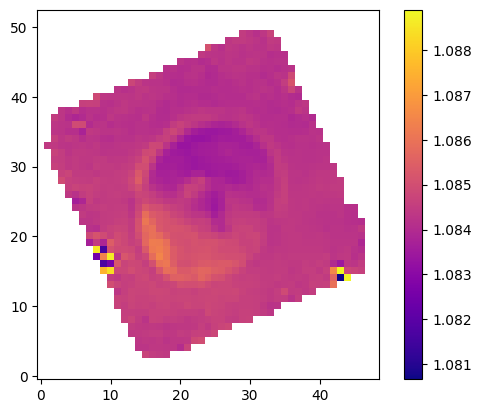

In [3]:
spec_slice = p.spectrum_slice(1.08, 1.09)

def find_mu(row, col):
    spec, background = p.get_spectrum(col+1, row+1)
    if background is None:
        return np.nan

    mu, *_ = p.fit_normal(spec, background, spec_slice)
    return mu

# print(p.data[0, :, :].shape)
rows, cols = np.indices(p.data[0, :, :].shape)
he_wavelengths = np.vectorize(find_mu)(rows, cols)

plt.imshow(he_wavelengths, origin="lower", cmap="plasma")
plt.colorbar()


Crop supernova

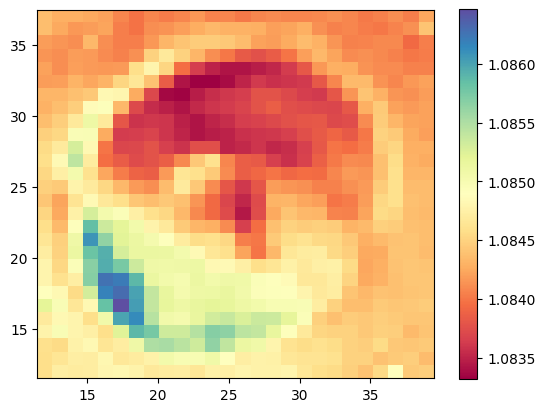

In [4]:

x1, x2 = 12, 40
y1, y2 = 12, 38
# x1, x2 = 0, 49+1
# y1, y2 = 0, 53+1
img = he_wavelengths[x1:x2, y1:y2]

plt.imshow(img, origin="lower", cmap="Spectral", extent=[x1-0.5, x2-0.5, y1-0.5, y2-0.5])
# ax.add_patch(ellipse)
plt.colorbar()

Overlay ellipse

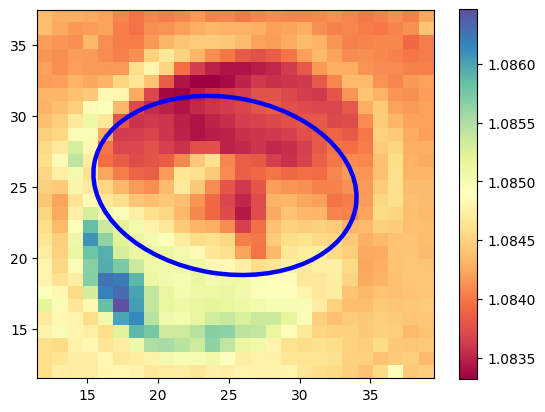

In [5]:
from matplotlib.patches import Ellipse

fig, ax = plt.subplots()

cx              = 24.739612579345703
cy              = 25.10753059387207
a               = 12.442249298095703
b               = 18.701356887817383
angle           = 80.83381652832031

ellipse = Ellipse(
    xy=(cx, cy),
    width=a,
    height=b,
    angle=angle,
    fill=False,
    edgecolor="blue",
    linewidth=3.2
)

im = ax.imshow(img, origin="lower", cmap="Spectral", extent=[x1-0.5, x2-0.5, y1-0.5, y2-0.5])
ax.add_patch(ellipse)
fig.colorbar(im, ax=ax)

Cutout ellipse to analyze speed

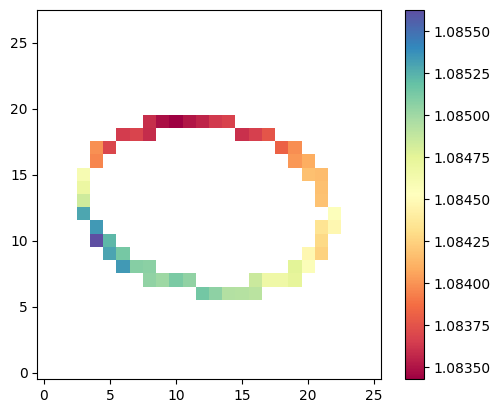

In [6]:
cx              = 24.739612579345703
cy              = 25.10753059387207
a               = 12.442249298095703
b               = 18.701356887817383
angle           = 80.83381652832031

def ellipse_curve(t_):
    t = t_*np.pi*2
    theta = angle / 180 * np.pi
    xp = a*np.cos(t)/2
    yp = b*np.sin(t)/2
    x = cx + xp*np.cos(theta) - yp*np.sin(theta)
    y = cy + xp*np.sin(theta) + yp*np.cos(theta)
    return x, y


mask = np.zeros(he_wavelengths.shape, dtype=np.bool)
for t in np.linspace(0, 1, 100):
    x, y = ellipse_curve(t)
    mask[int(y), int(x)] = True

ring = np.where(mask, he_wavelengths, np.nan)[x1:x2, y1:y2]
plt.imshow(ring, origin="lower", cmap="Spectral")
plt.colorbar()


### Calculate speed from wavelength

He wavelength at rest is $\lambda$=`1.08332`. Caluclate relative speed of each pixel of the ellipse

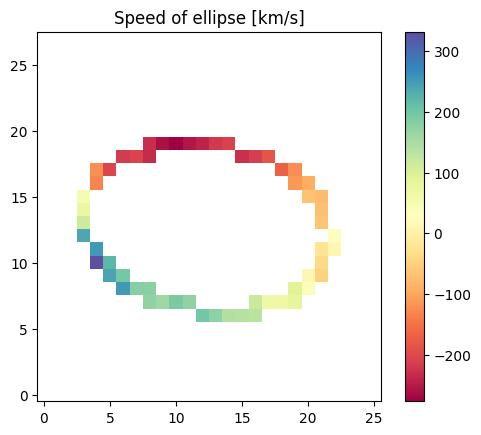

In [23]:
he_at_rest = 1.08332 

mean_speed = p.speed_from_doppler(he_at_rest, np.nanmean(ring)) * 1e-3

speed = np.vectorize(lambda x: np.nan if np.isnan(x) else p.speed_from_doppler(he_at_rest, x) * 1e-3)(ring) - mean_speed

plt.title("Speed of ellipse [km/s]")
plt.imshow(speed, origin="lower", cmap="Spectral")
plt.colorbar()

